[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zhiyunli/cpsc5610-labs/blob/main/week4/week4_lab_inclass_solution.ipynb)

# SOLUTION — Week 4 Lab (Wednesday): Training Real Networks with PyTorch

This lab goes with Lecture 7. It has **four short exercises**. We'll do each one right after the slides on the same idea.

| Exercise | Topic | Time |
|---|---|---|
| 1 | Train an MLP with mini-batches | 13 min |
| 2 | Evaluate it correctly | 8 min |
| 3 | An image classifier | 17 min |
| 4 | Save, load, and check | 7 min |

**How to use it:** replace every `[YOUR CODE]` with one line of code. Some steps ask you to **predict first**: write your guess before you run the cell. Run the cells from top to bottom. Later
exercises reuse names from earlier ones (`device`, `train`, `train_data`, ...).

**First:** choose *Runtime → Change runtime type → T4 GPU*, then run the setup cell below. It downloads the data
while we talk.

## Setup (run this first)

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("torchmetrics") is None:           # Colab doesn't always have it
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchmetrics"], check=True)

import torch
import torch.nn as nn
import torchmetrics
import torchvision
import torchvision.transforms.v2 as T
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("device:", device)

# California housing, prepared exactly as in Lecture 6
housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)
X_train = torch.FloatTensor(X_train)
means = X_train.mean(dim=0, keepdims=True)
stds = X_train.std(dim=0, keepdims=True)
X_train = (X_train - means) / stds
X_valid = (torch.FloatTensor(X_valid) - means) / stds
y_train = torch.FloatTensor(y_train).reshape(-1, 1)
y_valid = torch.FloatTensor(y_valid).reshape(-1, 1)
n_features = X_train.shape[1]

# Fashion MNIST, for exercise 3
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
train_and_valid_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor)
torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(train_and_valid_data, [55_000, 5_000])
class_names = train_and_valid_data.classes
print("housing:", X_train.shape, "  fashion:", len(train_data), len(valid_data))

device: cuda
housing: torch.Size([11610, 8])   fashion: 55000 5000


---
## Exercise 1: Train an MLP with mini-batches (13 min)

This MLP is a little **different** from the one on the slides. Predict its size before you run anything.

**1a.** Build an MLP with `nn.Sequential`: 8 inputs → 64 units → ReLU → 32 units → ReLU → 1 output.
**Before you run it:** how many parameters does it have? Count the weights and biases of each layer, as on the slides.

*My prediction:*

In [2]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(n_features, 64), nn.ReLU(),  # first layer and its activation
    nn.Linear(64, 32), nn.ReLU(),  # second layer and its activation
    nn.Linear(32, 1),  # the output layer
).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))   # does it match your prediction?

parameters: 2689


**1b.** Make a `DataLoader` with batches of **64**, shuffled.
**Before you run it:** how many batches are there per epoch, and how many rows are in the last one?

*My prediction:*

In [3]:
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)  # train_loader = ... (batches of 64, shuffled)
print("batches per epoch:", len(train_loader))
print("rows in the last batch:", len(train_dataset) - (len(train_loader) - 1) * 64)

batches per epoch: 182
rows in the last batch: 26


**1c.** Fill in the five phases of the training loop: forward, loss, backward, step, reset.

In [4]:
def train(model, optimizer, criterion, train_loader, n_epochs):
    model.train()
    for epoch in range(n_epochs):
        total_loss = 0.
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)  # forward
            loss = criterion(y_pred, y_batch)  # loss
            total_loss += loss.item()
            loss.backward()  # backward
            optimizer.step()  # step
            optimizer.zero_grad()  # reset
        print(f"Epoch {epoch + 1}/{n_epochs}, Loss: {total_loss / len(train_loader):.4f}")

**1d.** Train for 10 epochs. The printed loss (the average over each epoch's batches) should fall to about 0.35. (Small differences between machines are normal.)

In [5]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)
mse = nn.MSELoss()
train(model, optimizer, mse, train_loader, n_epochs=10)

Epoch 1/10, Loss: 0.8099


Epoch 2/10, Loss: 0.4631


Epoch 3/10, Loss: 0.4105
Epoch 4/10, Loss: 0.3899


Epoch 5/10, Loss: 0.3821
Epoch 6/10, Loss: 0.3701


Epoch 7/10, Loss: 0.3612


Epoch 8/10, Loss: 0.3586
Epoch 9/10, Loss: 0.3531


Epoch 10/10, Loss: 0.3510


*If you finish early:* build the model again (run 1a), and train it with `lr=0.05`. What happens to the loss?

---
## Exercise 2: Evaluate it correctly (8 min)

**2a.** Finish `evaluate()`: switch the model to evaluation mode, and turn off gradient tracking.

In [6]:
valid_loader = DataLoader(TensorDataset(X_valid, y_valid), batch_size=32)

def evaluate(model, data_loader, metric_fn, aggregate_fn=torch.mean):
    model.eval()  # evaluation mode
    metrics = []
    with torch.no_grad():  # no gradient tracking
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            metrics.append(metric_fn(model(X_batch), y_batch))
    return aggregate_fn(torch.stack(metrics))

def rmse(y_pred, y_true):
    return ((y_pred - y_true) ** 2).mean().sqrt()

print("mean of the batch RMSEs:", evaluate(model, valid_loader, rmse).item())

mean of the batch RMSEs: 0.5947429537773132


**2b.** Now compute the RMSE of the whole validation set **yourself**, without TorchMetrics. Go through the batches
and keep two running totals: the sum of the squared errors, and the number of rows. Take the square root only once,
at the very end.

In [7]:
total_sq_error, n_rows = 0.0, 0
model.eval()
with torch.no_grad():
    for X_batch, y_batch in valid_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_pred = model(X_batch)
        total_sq_error += ((y_pred - y_batch) ** 2).sum().item()  # total_sq_error += ... (this batch's squared errors, summed)
        n_rows += len(y_batch)  # n_rows += ... (this batch's number of rows)
my_rmse = (total_sq_error / n_rows) ** 0.5  # my_rmse = ... (one square root, at the end)
print("my RMSE of the whole set:", my_rmse)

my RMSE of the whole set: 0.6592467001695731


**2c.** Check your number against TorchMetrics. Nothing to fill in here: just run it.

In [8]:
rmse_metric = torchmetrics.MeanSquaredError(squared=False).to(device)
with torch.no_grad():
    for X_batch, y_batch in valid_loader:
        rmse_metric.update(model(X_batch.to(device)), y_batch.to(device))
print("TorchMetrics:", rmse_metric.compute().item())

TorchMetrics: 0.6592466831207275


**Question:** your RMSE and TorchMetrics should agree. Why does the mean of the batch RMSEs come out lower?
*(Write your answer here.)*

**Answer (solution copy only).** The square root shrinks big numbers more than small ones. Each batch's square root is
taken *before* averaging, so the batches with large errors get squeezed first, and the average comes out too low.

*Tiny example:* batch MSEs 0 and 4 give batch RMSEs 0 and 2, whose mean is 1. The true RMSE is
$\sqrt{(0 + 4)/2} = \sqrt{2} \approx 1.41$.

*Why it is always lower:* call each batch's RMSE $a$, so its MSE is $a^2$. Then

$$\text{mean}(a^2) = \text{mean}(a)^2 + \text{var}(a) \;\ge\; \text{mean}(a)^2,
\quad\text{so}\quad \text{mean}(a) \le \sqrt{\text{mean}(a^2)}.$$

The right side is (almost exactly) the true RMSE. The two are equal only if every batch has the same error, and the
gap grows with how uneven the batches are. Here one batch holds Monday's strange district (1,243 people per home). Its
RMSE is about 3.1, while the median batch is about 0.56, so that batch alone adds most of the spread. (The last batch
has only 30 rows, which changes the 4th decimal, not the conclusion.)

---
## Exercise 3: An image classifier (17 min)

**3a.** Look at the data. Each image is 1 × 28 × 28: one channel (gray), 28 rows, 28 columns.

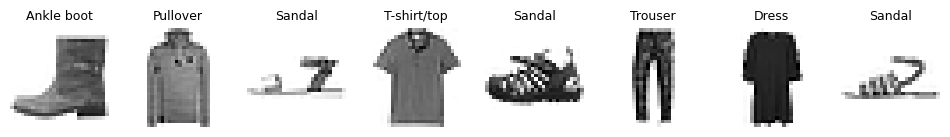

In [9]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="binary")
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.show()

**3b.** Write the classifier as a class, but this time **without** `nn.Sequential`. `__init__` already creates the
layers. In `forward`, call them yourself, one after another, and apply ReLU with `torch.relu(...)` after each hidden
layer. **No softmax at the end.**

In [10]:
class ImageClassifier(nn.Module):
    def __init__(self, n_inputs, n_hidden1, n_hidden2, n_classes):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden1 = nn.Linear(n_inputs, n_hidden1)
        self.hidden2 = nn.Linear(n_hidden1, n_hidden2)
        self.output = nn.Linear(n_hidden2, n_classes)

    def forward(self, X):
        Z = self.flatten(X)  # Z = ... (flatten: [batch, 1, 28, 28] -> [batch, 784])
        Z = torch.relu(self.hidden1(Z))  # Z = ... (the first hidden layer, then ReLU)
        Z = torch.relu(self.hidden2(Z))  # Z = ... (the second hidden layer, then ReLU)
        return self.output(Z)  # return ... (the output layer: one logit per class)

torch.manual_seed(42)
model = ImageClassifier(n_inputs=28 * 28, n_hidden1=300, n_hidden2=100, n_classes=10).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))   # should print 266610

parameters: 266610


**3c.** Choose the loss for classification into 10 classes, and train for 2 epochs with your `train()` from exercise 1.

In [11]:
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=256)
xentropy = nn.CrossEntropyLoss()  # xentropy = ... (the loss for multiclass classification)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
train(model, optimizer, xentropy, train_loader, n_epochs=2)

Epoch 1/2, Loss: 0.6289


Epoch 2/2, Loss: 0.4015


**3d.** Measure the validation accuracy **yourself**: for each batch, find the predicted class of each image (the
largest logit), and count how many match the labels. You should get about 85%.

In [12]:
def accuracy_of(model, data_loader):
    correct, total = 0, 0
    model.eval()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch).argmax(dim=1)  # y_pred = ... (the predicted class of each image: no softmax needed)
            correct += (y_pred == y_batch).sum().item()  # correct += ... (how many in this batch are right)
            total += len(y_batch)
    return correct / total

print("validation accuracy:", accuracy_of(model, valid_loader))

validation accuracy: 0.851


**3e.** Look at some predictions. Which mistakes does the model make? Do they make sense?

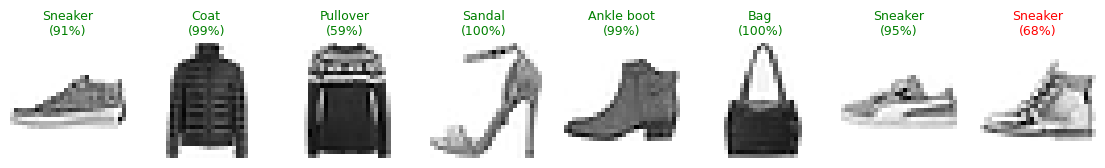

In [13]:
X_new, y_new = next(iter(valid_loader))
X_new, y_new = X_new[:8].to(device), y_new[:8]
with torch.no_grad():
    logits = model(X_new)
y_proba = torch.softmax(logits, dim=1)   # probabilities, only to show them
y_pred = logits.argmax(dim=1).cpu()      # the class: argmax works on the logits directly

fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, image, true, pred, p in zip(axes, X_new.cpu(), y_new, y_pred, y_proba.max(dim=1).values.cpu()):
    ax.imshow(image.squeeze(), cmap="binary")
    ax.set_title(f"{class_names[pred]}\n({p:.0%})", fontsize=9, color="green" if pred == true else "red")
    ax.axis("off")
plt.show()

---
## Exercise 4: Save, load, and check (7 min)

**4a.** Save only the learned weights: the model's `state_dict()`.

In [14]:
torch.save(model.state_dict(), "my_fashion_model.pt")  # save the weights

**4b.** Build a new, untrained model with the same shape, and load the weights into it.

In [15]:
new_model = ImageClassifier(n_inputs=28 * 28, n_hidden1=300, n_hidden2=100, n_classes=10).to(device)
new_model.load_state_dict(torch.load("my_fashion_model.pt", weights_only=True))  # load the weights
new_model.eval()

ImageClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden1): Linear(in_features=784, out_features=300, bias=True)
  (hidden2): Linear(in_features=300, out_features=100, bias=True)
  (output): Linear(in_features=100, out_features=10, bias=True)
)

**4c.** Check the reloaded model two ways: its outputs on `X_new` are exactly equal to the old model's, and its
validation accuracy (use your `accuracy_of()` from 3d) is the same as in exercise 3.

In [16]:
with torch.no_grad():
    same = torch.equal(new_model(X_new), model(X_new))  # same = ... (True if the outputs are exactly equal)
print("same outputs:", same)                                       # should print True
print("reloaded accuracy:", accuracy_of(new_model, valid_loader))  # print the reloaded model's validation accuracy

same outputs: True


reloaded accuracy: 0.851


**Question:** why do we save the `state_dict()`, and not the whole model object?
*(Write your answer here.)*

*If you finish early:* **predict first**, then run the cell below. It loads the same file into a model with 200
units in the first hidden layer, not 300. What happens, and why?

In [17]:
wrong_model = ImageClassifier(n_inputs=28 * 28, n_hidden1=200, n_hidden2=100, n_classes=10).to(device)
try:
    wrong_model.load_state_dict(torch.load("my_fashion_model.pt", weights_only=True))
except RuntimeError as error:
    print(str(error).split("\n")[1].strip())

size mismatch for hidden1.weight: copying a param with shape torch.Size([300, 784]) from checkpoint, the shape in current model is torch.Size([200, 784]).


**4d.** Keep your file. Files in Colab are deleted when the runtime ends. Either download it (Files panel on the left,
or run the first two lines below in a new cell), or save it to your Google Drive (the last three lines):

```python
from google.colab import files
files.download("my_fashion_model.pt")

from google.colab import drive
drive.mount("/content/drive")
torch.save(model.state_dict(), "/content/drive/MyDrive/my_fashion_model.pt")
```

---
## Exit questions: just for you

Nothing to hand in. Take two minutes and think each one through. If you can't answer one in a sentence or two,
go back to that part of the slides or this notebook.

1. Why does the classifier end without a softmax?
2. Why is the average of the batch RMSEs not the RMSE of the whole validation set?
3. What was the most confusing part of today? Bring that question to class on Monday.